# Can an ML model beat Kalshi prices?

This notebook walks through the whole project: **data → features → model → backtest → live check**.
It loads the cached data in `data/`, so it runs in about a minute. The one-hour download is
optional (see the *Refresh data* cell).

**Question:** given what a trader could see at some moment (price, spread, volume, time left),
is a market's YES price systematically wrong, by enough to profit after Kalshi's fees?

**Short answer (run of 2026-09-23):** not yet. Overall the model is slightly *worse* than the
market price on a later, held-out period. It does beat the market in Weather, Commodities and
Financials, and a live sanity check found a flaw (longshot inflation) to fix next.
Details below.

In [1]:
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

from kalshi import collect, features as F, train as T, backtest as B

DATA = collect.DATA
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.grid": True, "grid.color": "#ecebe6", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "font.size": 10})
pd.set_option("display.float_format", "{:.4f}".format)

### Refresh data (optional)
Set `REFRESH = True` to re-crawl Kalshi's public API. That takes about an hour; it's resumable and
cached, and needs no API key. Leave it `False` to use the saved data.

In [2]:
REFRESH = False
if REFRESH:
    collect.run(min_volume=500)
    F.run()

## 1. Which markets?

Kalshi lists thousands of series. We keep **recurring, short-dated ones**: sports games, daily
weather, commodity and index price ranges, weekly entertainment charts.

**Why not everything?** We can only learn from markets that have already *settled*. Take a long-dated
market like "Will X happen by 2027?". It's only settled today if X *already happened*, which
means it resolved YES early. Including those would teach the model that longshots hit far more
often than they really do. Recurring short-dated markets close on a schedule, so whether they're
in the dataset doesn't depend on how they resolved.

13,326 markets from 321 series, closing Jul 17 to Sep 23, 2026


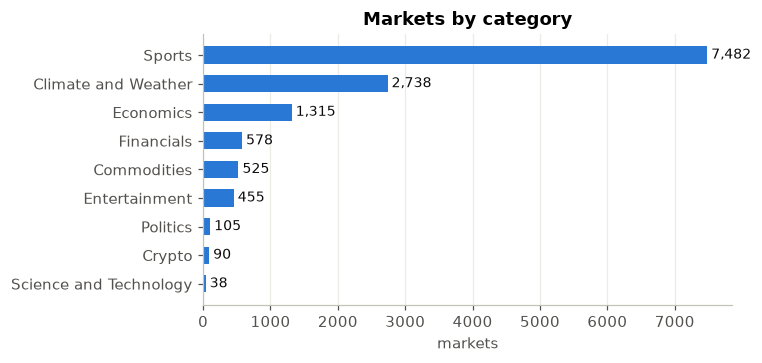

In [3]:
markets = pd.read_parquet(DATA / "markets.parquet")
print(f"{len(markets):,} markets from {markets.series_ticker.nunique()} series, "
      f"closing {markets.close_time.min():%b %d} to {markets.close_time.max():%b %d, %Y}")

counts = markets.category.value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(counts.index, counts.values, color=BLUE, height=0.6)
for y, v in enumerate(counts.values):
    ax.text(v, y, f" {v:,}", va="center", color=INK, fontsize=9)
ax.set(title="Markets by category", xlabel="markets"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**A second safeguard.** Even within recurring series, some markets close *as soon as* the event
happens (for example "Will the video pass N views?"). For those, a YES outcome means an earlier
close. We compare typical lifetimes of YES and NO markets per series and drop any series where YES
markets close more than 15% of their lifetime earlier:

In [4]:
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):  # reads the cached crawl; hide progress lines
    events = collect.crawl_series(None, {p.stem: "" for p in (DATA / "series_events").glob("*.json")},
                                  DATA / "series_events")
allm = collect.to_frame(collect.market_rows(events))
allm = allm[allm.life_days <= collect.MAX_LIFE_DAYS]
bad = collect.outcome_dependent_series(allm)
life = allm[allm.series_ticker.isin(bad)].groupby(["series_ticker", "result"]).life_days.median().unstack()
life.columns = ["median life if NO (days)", "median life if YES (days)"]
display(life.round(2))

,median life if NO (days),median life if YES (days)
series_ticker,,
KXBIGGESTQUAKE,1.1700,0.7500
KXNFLFFWEEKTOP,5.4700,4.2700
KXNFLWEEKMOSTPASSYDS,12.8400,9.6500
KXTOPALBUM,11.5400,6.3700
KXUSDJPYAW,4.3100,2.9900
KXUSDMXNAW,4.3100,2.9400
KXUSDSEKAW,4.3100,3.0800
KXYTVIEWSW,7.5100,2.1400


## 2. Snapshots and features

Each training row is a **snapshot**: one market at one moment, built only from the hourly price
history *up to that moment*. We sample up to 6 random hourly snapshots over each market's life.

> We deliberately do *not* use "24 hours before close". Many markets close the moment the event
> resolves, so anchoring on close time quietly tells the model when the answer arrived.

Features include the mid price and its log-odds, the spread, 1h/6h/24h price moves, volatility,
volume, open interest, hours since the last trade, market age, hours to close and category.
The trade price used later is the **ask at that moment**, so the spread is always paid.

In [5]:
df = pd.read_parquet(DATA / "features.parquet")
df = df[df.y >= 0]
print(f"{len(df):,} snapshots | {df.ticker.nunique():,} markets | {df.event_ticker.nunique():,} events | "
      f"YES rate {df.y.mean():.1%}")
display(df[F.FEATURES + ["y"]].head())

73,272 snapshots | 12,427 markets | 8,170 events | YES rate 40.5%


,mid,logit_mid,spread,dist_half,ask,bid,d_mid_1h,d_mid_6h,d_mid_24h,vol_mid_24h,log_vol_1h,log_vol_24h,log_vol_cum,log_oi,age_h,hours_to_close,life_frac,hours_since_trade,category,y
0,0.9650,3.3168,0.0100,0.4650,0.9700,0.9600,0.0000,0.0200,0.0000,0.0048,0.0000,7.9215,7.9215,7.9017,29.3333,131.9833,0.1818,1.0000,Economics,1
1,0.9850,4.1846,0.0100,0.4850,0.9900,0.9800,0.0000,0.0050,0.0100,0.0021,0.0000,6.9187,8.8580,7.8517,66.3333,94.9833,0.4112,22.0000,Economics,1
2,0.9800,3.8918,0.0200,0.4800,0.9900,0.9700,0.0000,-0.0050,0.0150,0.0028,0.0000,8.3606,8.8580,7.8517,54.3333,106.9833,0.3368,10.0000,Economics,1
3,0.9650,3.3168,0.0100,0.4650,0.9700,0.9600,0.0000,0.0000,0.0000,0.0048,0.0000,7.9215,7.9215,7.9017,33.3333,127.9833,0.2066,5.0000,Economics,1
4,0.9650,3.3168,0.0500,0.4650,0.9900,0.9400,0.0000,0.0000,0.0000,0.0035,0.0000,0.0000,0.0000,0.0000,5.3333,155.9833,0.0331,999.0000,Economics,1


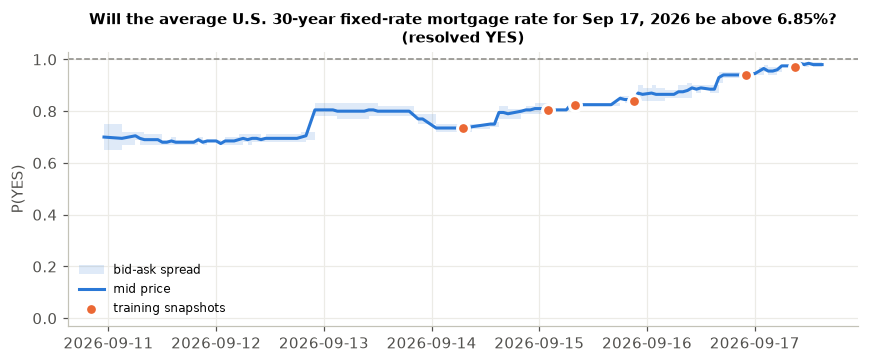

In [6]:
# One market's life: bid/ask band, mid price, sampled snapshots and the final outcome
ex = df.groupby("ticker").filter(lambda d: len(d) >= 5).query("0.2 < mid < 0.8").ticker.iloc[0]
m = markets.set_index("ticker").loc[ex]
c = F.prepare_candles(pd.read_parquet(DATA / "candles" / f"{ex}.parquet"))
t = pd.to_datetime(c.t, unit="s")
snaps = df[df.ticker == ex]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.fill_between(t, c.bid, c.ask, step="post", color=BLUE, alpha=0.15, lw=0, label="bid-ask spread")
ax.plot(t, c.mid, color=BLUE, lw=2, label="mid price")
ax.scatter(pd.to_datetime(snaps.t0, unit="s"), snaps.mid, s=60, color=ORANGE, zorder=3,
           edgecolor="white", linewidth=2, label="training snapshots")
ax.axhline(1 if m.result == "yes" else 0, color=GRAY, ls="--", lw=1)
ax.set(title=f"{m.title}\n(resolved {m.result.upper()})", ylabel="P(YES)", ylim=(-0.03, 1.03))
ax.title.set_fontsize(10); ax.legend(loc="best", frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Leakage check:** rebuild 200 random snapshots from price history *cut off* at the snapshot time. The features must come out identical.

In [7]:
F.check_no_leakage(df, DATA / 'candles')

leakage check passed on 200 snapshots


## 3. The model

The market price is already a strong forecast, so we don't ask the model to predict from scratch.
LightGBM starts **from the market's own log-odds** and learns only a *correction*. If it learns
nothing, it simply returns the market price. A 2-parameter calibration step follows.

**Split by time, not at random** (random splits leak, because markets that close together are
correlated):
- **Train:** markets that closed before T1.
- **Validation:** snapshots between T1 and T2, used for early stopping and calibration.
- **Test:** snapshots after T2, touched only for the final numbers.

We score with the **Brier score** (mean squared error of the probability; lower is better).

In [8]:
tr, va, te, (t1, t2) = T.split(df)
fmt = lambda x: pd.Timestamp(x, unit="s").strftime("%b %d")
print(f"train: {tr.ticker.nunique():,} markets closed before {fmt(t1)}\n"
      f"val:   {va.ticker.nunique():,} markets\n"
      f"test:  {te.ticker.nunique():,} markets, snapshots from {fmt(t2)} onward")

model = T.fit(tr, va)
from sklearn.linear_model import LogisticRegression
recal = LogisticRegression(C=1e6).fit(F._logit(tr.mid.to_numpy()).reshape(-1, 1), tr.y, sample_weight=tr.w)
p_model = model.predict(te)
preds = {"market_mid": te.mid.to_numpy(),
         "market_recalibrated": recal.predict_proba(F._logit(te.mid.to_numpy()).reshape(-1, 1))[:, 1],
         "model": p_model}
rep = T.report(te, preds)
display(rep.round(4))
v = rep.loc["model", "brier_vs_market_%"]
display(Markdown(f"**The model is {abs(v):.1f}% {'worse' if v > 0 else 'better'} than the market price on the test period.** "
                 "Recalibrating the market price alone changes almost nothing, so there's no simple "
                 "favorite-longshot bias to exploit."))

train: 7,382 markets closed before Sep 05
val:   2,260 markets
test:  2,450 markets, snapshots from Sep 16 onward


,brier,logloss,brier_vs_market_%
model,,,
market_mid,0.1840,0.5375,0.0000
market_recalibrated,0.1840,0.5373,0.0053
model,0.1875,0.5445,1.9005


**The model is 1.9% worse than the market price on the test period.** Recalibrating the market price alone changes almost nothing, so there's no simple favorite-longshot bias to exploit.

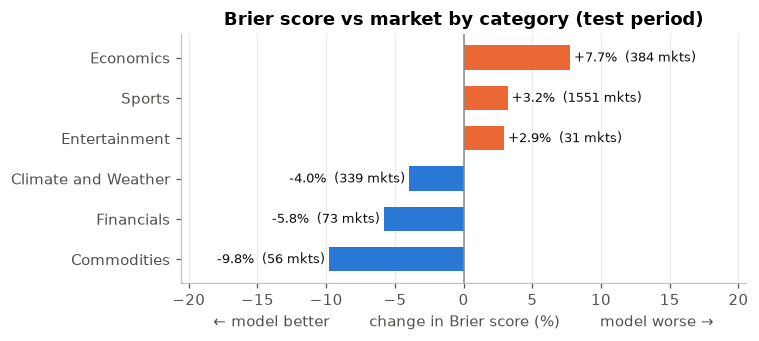

In [9]:
bc = T.breakdown(te, p_model, "category")
bc = bc[bc.markets >= 20]
bc["change"] = 100 * (bc.brier_model / bc.brier_market - 1)
bc = bc.sort_values("change")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(bc.index.astype(str), bc.change, color=np.where(bc.change < 0, BLUE, ORANGE), height=0.6)
for y, (v, n) in enumerate(zip(bc.change, bc.markets)):
    ax.text(v, y, f" {v:+.1f}%  ({int(n)} mkts) " , va="center", ha="left" if v >= 0 else "right",
            color=INK, fontsize=8.5)
ax.axvline(0, color=GRAY, lw=1)
lim = max(abs(bc.change).max() * 2.1, 5); ax.set_xlim(-lim, lim)
ax.set(title="Brier score vs market by category (test period)",
       xlabel="← model better        change in Brier score (%)        model worse →")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

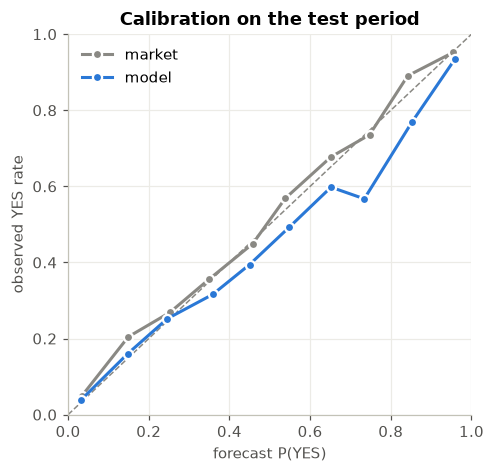

In [10]:
# Reliability: when a forecast says 30%, does YES happen ~30% of the time?
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
for name, p, col in [("market", te.mid.to_numpy(), GRAY), ("model", p_model, BLUE)]:
    b = np.clip(np.digitize(p, bins) - 1, 0, 9)
    g = pd.DataFrame(dict(b=b, p=p, y=te.y, w=te.w)).groupby("b").apply(
        lambda d: pd.Series(dict(p=np.average(d.p, weights=d.w), y=np.average(d.y, weights=d.w))))
    ax.plot(g.p, g.y, "o-", color=col, lw=2, ms=6, mec="white", mew=1.5, label=name)
ax.set(title="Calibration on the test period", xlabel="forecast P(YES)", ylabel="observed YES rate",
       xlim=(0, 1), ylim=(0, 1)); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Points on the dashed diagonal mean well calibrated. The market hugs it. The model's line sits
**below** it from about 40% up: when it says 70%, YES happens only about 57% of the time. It
overrates YES outcomes, the same flaw the bracket check in section 5 exposes.

### Why "it worked in training" isn't enough
On validation slices *inside* the training period, every model variant beat the market by
about 1.5%. On the later test period that edge disappeared. The patterns didn't carry forward:
the test window starts as football season opens and the summer baseball-heavy mix ends.
That's why the test set has to come **after** the training data.

## 4. Backtest (after fees)

Rules: on the test period, take **one trade per market** at the first snapshot where the model's
edge exceeds a margin. Buy YES at the ask, or NO at 1 − bid, pay Kalshi's taker fee
`ceil(0.07 × P × (1−P))`, and hold to settlement.

The confidence interval comes from **resampling whole events**, because outcomes inside one event
are correlated.

In [11]:
te_p = te.assign(p_model=p_model)
sweep = pd.DataFrame({m: B.summarize(B.pick_trades(te_p, m)) for m in [0.0, 0.02, 0.05, 0.10]}).T
sweep.index.name = "min edge"
display(sweep[["trades", "events", "hit_rate", "avg_price", "roi_flat", "roi_ci_lo", "roi_ci_hi"]].round(3))

,trades,events,hit_rate,avg_price,roi_flat,roi_ci_lo,roi_ci_hi
min edge,,,,,,,
0.0000,1746.0000,1328.0000,0.5180,0.5130,-0.0240,-0.0600,0.0110
0.0200,1256.0000,1036.0000,0.5100,0.5020,-0.0190,-0.0630,0.0230
0.0500,577.0000,511.0000,0.5110,0.4920,0.0010,-0.0710,0.0710
0.1000,84.0000,69.0000,0.4640,0.3180,0.3900,0.0850,0.7120


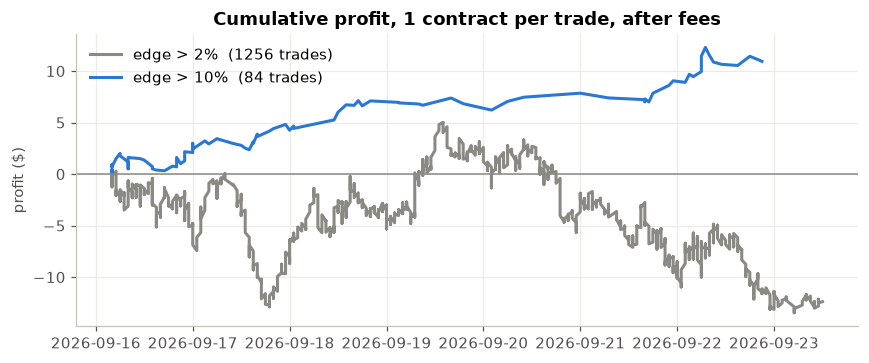

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for m, col in [(0.02, GRAY), (0.10, BLUE)]:
    tt = B.pick_trades(te_p, m).sort_values("t0")
    ax.plot(pd.to_datetime(tt.t0, unit="s"), tt.pnl.cumsum(), color=col, lw=2,
            label=f"edge > {m:.0%}  ({len(tt)} trades)")
ax.axhline(0, color=GRAY, lw=1)
ax.set(title="Cumulative profit, 1 contract per trade, after fees", ylabel="profit ($)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

Small margins lose a little money; the range of likely outcomes includes zero. The 10¢ margin looks
great, but we picked it *after* seeing every margin's result, with few trades. Treat it as a
**hypothesis to confirm on future data**, not a proven edge.

## 5. Live sanity check: do the probabilities add up?

`python run.py predict` scores currently open markets (results are saved to `data/live_edges.csv`).
For a set of **mutually exclusive brackets** (e.g. "WTI settles between $91 and $92"), exactly
one bracket wins, so the probabilities should sum to about 1. The market's do. The model's don't:

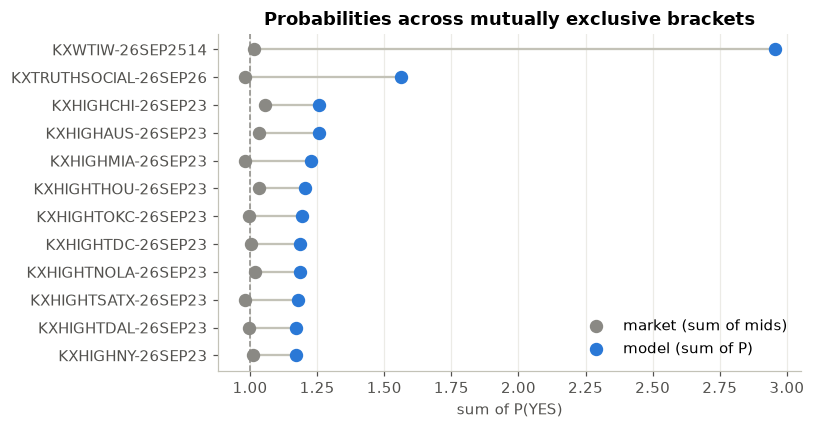

live scores from: 2026-09-23 16:23 UTC


In [13]:
live = pd.read_csv(DATA / "live_edges.csv")
live["event"] = live.ticker.str.rsplit("-", n=1).str[0]
br = live[live.ticker.str.contains("-B")].assign(mid=lambda d: (d.bid + d.ask) / 2)
s = br.groupby("event").agg(brackets=("ticker", "size"), market=("mid", "sum"), model=("p_model", "sum"))
s = s[s.brackets >= 4].sort_values("model").tail(12)

fig, ax = plt.subplots(figsize=(7.5, 4))
y = np.arange(len(s))
ax.scatter(s.market, y, color=GRAY, s=60, zorder=3, label="market (sum of mids)")
ax.scatter(s.model, y, color=BLUE, s=60, zorder=3, label="model (sum of P)")
ax.hlines(y, s.market, s.model, color="#c3c2b7", lw=1.5)
ax.axvline(1, color=GRAY, ls="--", lw=1)
ax.set_yticks(y, s.index); ax.set(title="Probabilities across mutually exclusive brackets", xlabel="sum of P(YES)")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("live scores from:", pd.Timestamp((DATA / "live_edges.csv").stat().st_mtime, unit="s").strftime("%Y-%m-%d %H:%M UTC"))

The model **inflates longshots**. That's why its "top edges" are almost all cheap commodity
brackets. Those signals aren't real, and fixing this is the first next step.

## 6. Conclusions and next steps

| | |
|---|---|
| **Built** | A leakage-checked pipeline: public-API crawl → point-in-time features → market-anchored model → fee-aware backtest → live scoring |
| **Found** | Kalshi prices on these markets are hard to beat from price and volume alone. Small edges appear in Weather, Commodities and Financials |
| **Flaw** | Probabilities within bracket sets don't sum to 1 (longshot inflation) |

**Next:**
1. Normalize probabilities within mutually exclusive events, then re-test.
2. Walk-forward evaluation over several consecutive test windows.
3. Specialized Weather and Commodities models with outside data (NOAA forecasts, futures prices).

*Read-only research tool. It never places orders, and nothing here is financial advice.*